# 📊 Feature-by-Feature Visualization Around Wildfire Smoke Arrival ($\tau = 0$)

Using the clean non-redundant dataset (`data/wildfire_smoke_simple.csv`), this notebook inspects:
1. The **4-panel benchmark verification figure** (PM2.5 rise above baseline, raw concentrations, atmospheric AOD + CO tracers, and iconic wildfire smoke monitors).
2. **What happens around $\tau = 0$ for every dynamic feature** across all `439` unique EPA stations (`Train = 358`, `Test = 81`).
3. A **single-monitor multi-feature trace** (`Banning, CA`, September 2024 Line Fire plume, Test split).
4. A quantitative **before vs. after $\tau = 0$ distribution summary** across all 18 dynamic features.

### 1. Load Libraries and the Simple Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean, non-redundant wildfire smoke dataset (one row per monitor per hour)
df = pd.read_csv('data/wildfire_smoke_simple.csv')

n_tot = df['sample_id'].nunique()
n_tr = df[df['split'] == 'train']['sample_id'].nunique()
n_te = df[df['split'] == 'test']['sample_id'].nunique()
print(f'Loaded simple dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Unique EPA stations: {n_tot} (Train={n_tr}, Test={n_te}), States={df["state"].nunique()}')
df.head(3)

Loaded simple dataset: 63,655 rows x 30 columns
Unique EPA stations: 439 (Train=358, Test=81), States=49


,sample_id,site_id,city,state,split,onset_utc,timestamp_utc,tau_hour,latitude,longitude,...,boundary_layer_height_m,wind_ms,wind_dir_sin,wind_dir_cos,temp_c,humidity_pct,pressure_hpa,rain_mm_hr,local_hour,smoke_trapping_index
0,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 05:00:00,-72,40.55013,-122.38092,...,830.0,3.41,-0.052336,-0.998629,28.3,19.0,983.1,0.0,21,0.032258
1,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 06:00:00,-71,40.55013,-122.38092,...,730.0,0.94,-0.848048,-0.529919,25.4,25.0,983.8,0.0,22,0.036145
2,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 07:00:00,-70,40.55013,-122.38092,...,630.0,0.92,-0.974370,-0.224951,23.4,32.0,984.4,0.0,23,0.027397


### 2. 4-Panel Overview Diagram (Reproducible Code for Benchmark Verification Plot)

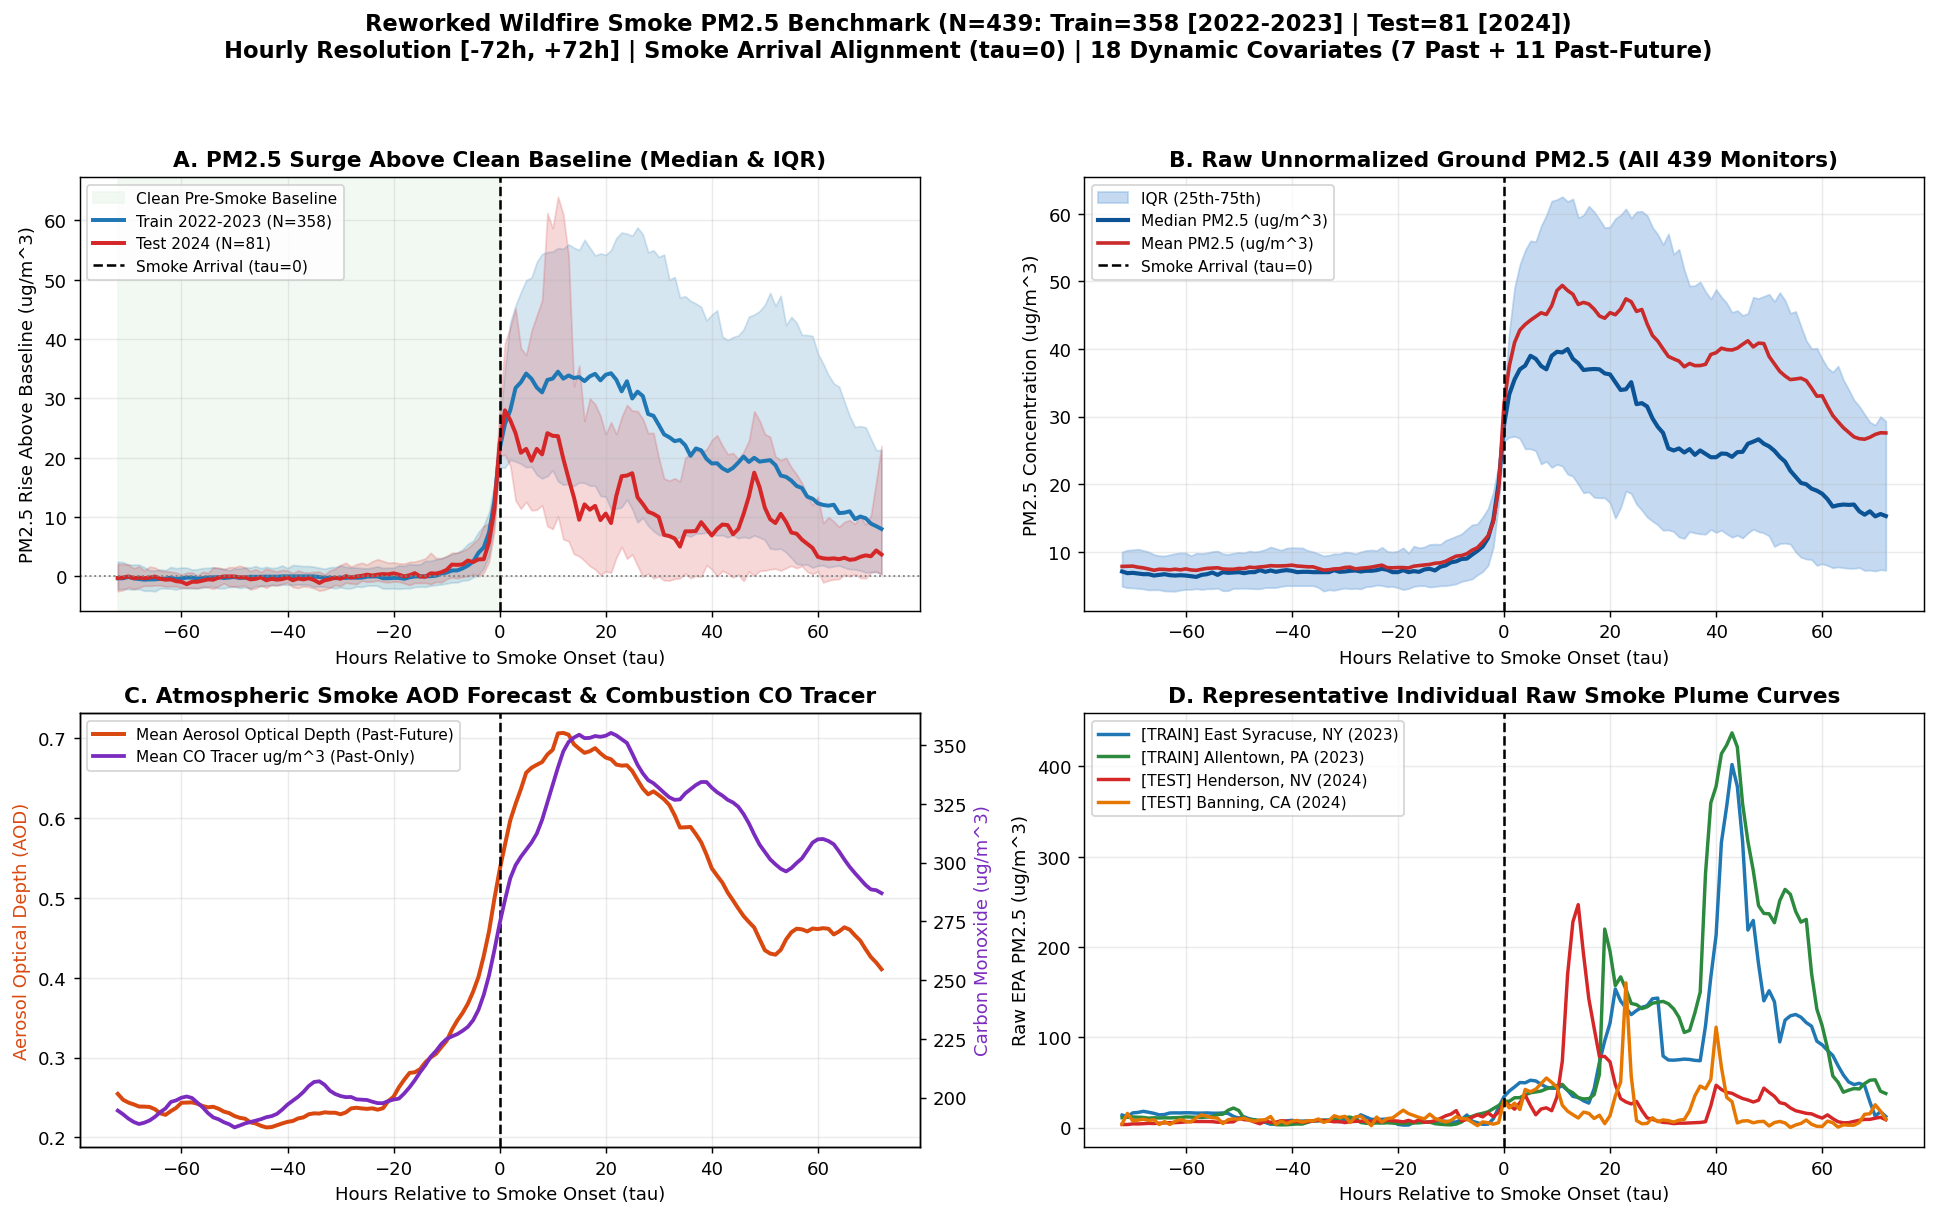

In [2]:
# Compute each station's clean pre-smoke baseline median PM2.5 (tau < 0)
pre_med = (
    df[df['tau_hour'] < 0]
    .groupby('sample_id')['pm25_ug_m3']
    .median()
    .rename('pre_med_pm25')
)
df = df.merge(pre_med, on='sample_id')
df['pm25_rise'] = df['pm25_ug_m3'] - df['pre_med_pm25']

n_tot = df['sample_id'].nunique()
n_tr = df[df['split'] == 'train']['sample_id'].nunique()
n_te = df[df['split'] == 'test']['sample_id'].nunique()

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5), dpi=130)
fig.suptitle(
    f'Reworked Wildfire Smoke PM2.5 Benchmark (N={n_tot}: Train={n_tr} [2022-2023] | Test={n_te} [2024])\n'
    'Hourly Resolution [-72h, +72h] | Smoke Arrival Alignment (tau=0) | 18 Dynamic Covariates (7 Past + 11 Past-Future)',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# --- Panel A: PM2.5 Rise Above Baseline (Train vs Test Median & IQR) ---
ax = axes[0, 0]
ax.axvspan(-72, 0, color='#e8f5e9', alpha=0.55, label='Clean Pre-Smoke Baseline')
for split_name, color, label in [('train', '#1f77b4', f'Train 2022-2023 (N={n_tr})'),
                                 ('test', '#d62728', f'Test 2024 (N={n_te})')]:
    sub = df[df['split'] == split_name]
    g = sub.groupby('tau_hour')['pm25_rise'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax.plot(g['tau_hour'], g['med'], color=color, lw=2.2, label=label)
    ax.fill_between(g['tau_hour'], g['q25'], g['q75'], color=color, alpha=0.18)

ax.axvline(0, color='black', ls='--', lw=1.4, label='Smoke Arrival (tau=0)')
ax.axhline(0, color='gray', ls=':', lw=1.0)
ax.set_title('A. PM2.5 Surge Above Clean Baseline (Median & IQR)', fontweight='bold')
ax.set_xlabel('Hours Relative to Smoke Onset (tau)')
ax.set_ylabel('PM2.5 Rise Above Baseline (ug/m^3)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel B: Raw Unnormalized PM2.5 Across All Monitors ---
ax = axes[0, 1]
raw_stats = df.groupby('tau_hour')['pm25_ug_m3'].agg(
    med='median',
    mean='mean',
    q25=lambda s: np.percentile(s, 25),
    q75=lambda s: np.percentile(s, 75),
).reset_index()
ax.fill_between(raw_stats['tau_hour'], raw_stats['q25'], raw_stats['q75'], color='#7faee0', alpha=0.45, label='IQR (25th-75th)')
ax.plot(raw_stats['tau_hour'], raw_stats['med'], color='#0b5394', lw=2.3, label='Median PM2.5 (ug/m^3)')
ax.plot(raw_stats['tau_hour'], raw_stats['mean'], color='#c92a2a', lw=2.0, label='Mean PM2.5 (ug/m^3)')
ax.axvline(0, color='black', ls='--', lw=1.4, label='Smoke Arrival (tau=0)')
ax.set_title(f'B. Raw Unnormalized Ground PM2.5 (All {n_tot} Monitors)', fontweight='bold')
ax.set_xlabel('Hours Relative to Smoke Onset (tau)')
ax.set_ylabel('PM2.5 Concentration (ug/m^3)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel C: Columnar Smoke AOD Forecast & Carbon Monoxide Tracer ---
ax = axes[1, 0]
ax_r = ax.twinx()
grp_f = df.groupby('tau_hour')[['aerosol_optical_depth', 'co_ug_m3']].mean().reset_index()
l_aod, = ax.plot(grp_f['tau_hour'], grp_f['aerosol_optical_depth'], color='#d9480f', lw=2.2, label='Mean Aerosol Optical Depth (Past-Future)')
l_co, = ax_r.plot(grp_f['tau_hour'], grp_f['co_ug_m3'], color='#7b2cbf', lw=2.1, label='Mean CO Tracer ug/m^3 (Past-Only)')
ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('C. Atmospheric Smoke AOD Forecast & Combustion CO Tracer', fontweight='bold')
ax.set_xlabel('Hours Relative to Smoke Onset (tau)')
ax.set_ylabel('Aerosol Optical Depth (AOD)', color='#d9480f')
ax_r.set_ylabel('Carbon Monoxide (ug/m^3)', color='#7b2cbf')
ax.grid(True, alpha=0.25)
ax.legend([l_aod, l_co], [l_aod.get_label(), l_co.get_label()], loc='upper left', fontsize=8.5)

# --- Panel D: Representative Individual Raw Smoke Plume Traces ---
ax = axes[1, 1]
for sid_str, col, lbl in [
    ('36-067-1015', '#1f77b4', '[TRAIN] East Syracuse, NY (2023)'),
    ('42-077-0004', '#2b8a3e', '[TRAIN] Allentown, PA (2023)'),
    ('32-003-0298', '#d62728', '[TEST] Henderson, NV (2024)'),
    ('06-065-1016', '#e67700', '[TEST] Banning, CA (2024)'),
]:
    sub = df[df['site_id'] == sid_str].sort_values('tau_hour')
    if not sub.empty:
        ax.plot(sub['tau_hour'], sub['pm25_ug_m3'], color=col, lw=1.9, label=lbl)

ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('D. Representative Individual Raw Smoke Plume Curves', fontweight='bold')
ax.set_xlabel('Hours Relative to Smoke Onset (tau)')
ax.set_ylabel('Raw EPA PM2.5 (ug/m^3)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('data/wildfire_smoke_verification.png', dpi=150, bbox_inches='tight')
plt.show()

### 3. What Happens Around $\tau = 0$ for Every Single Feature

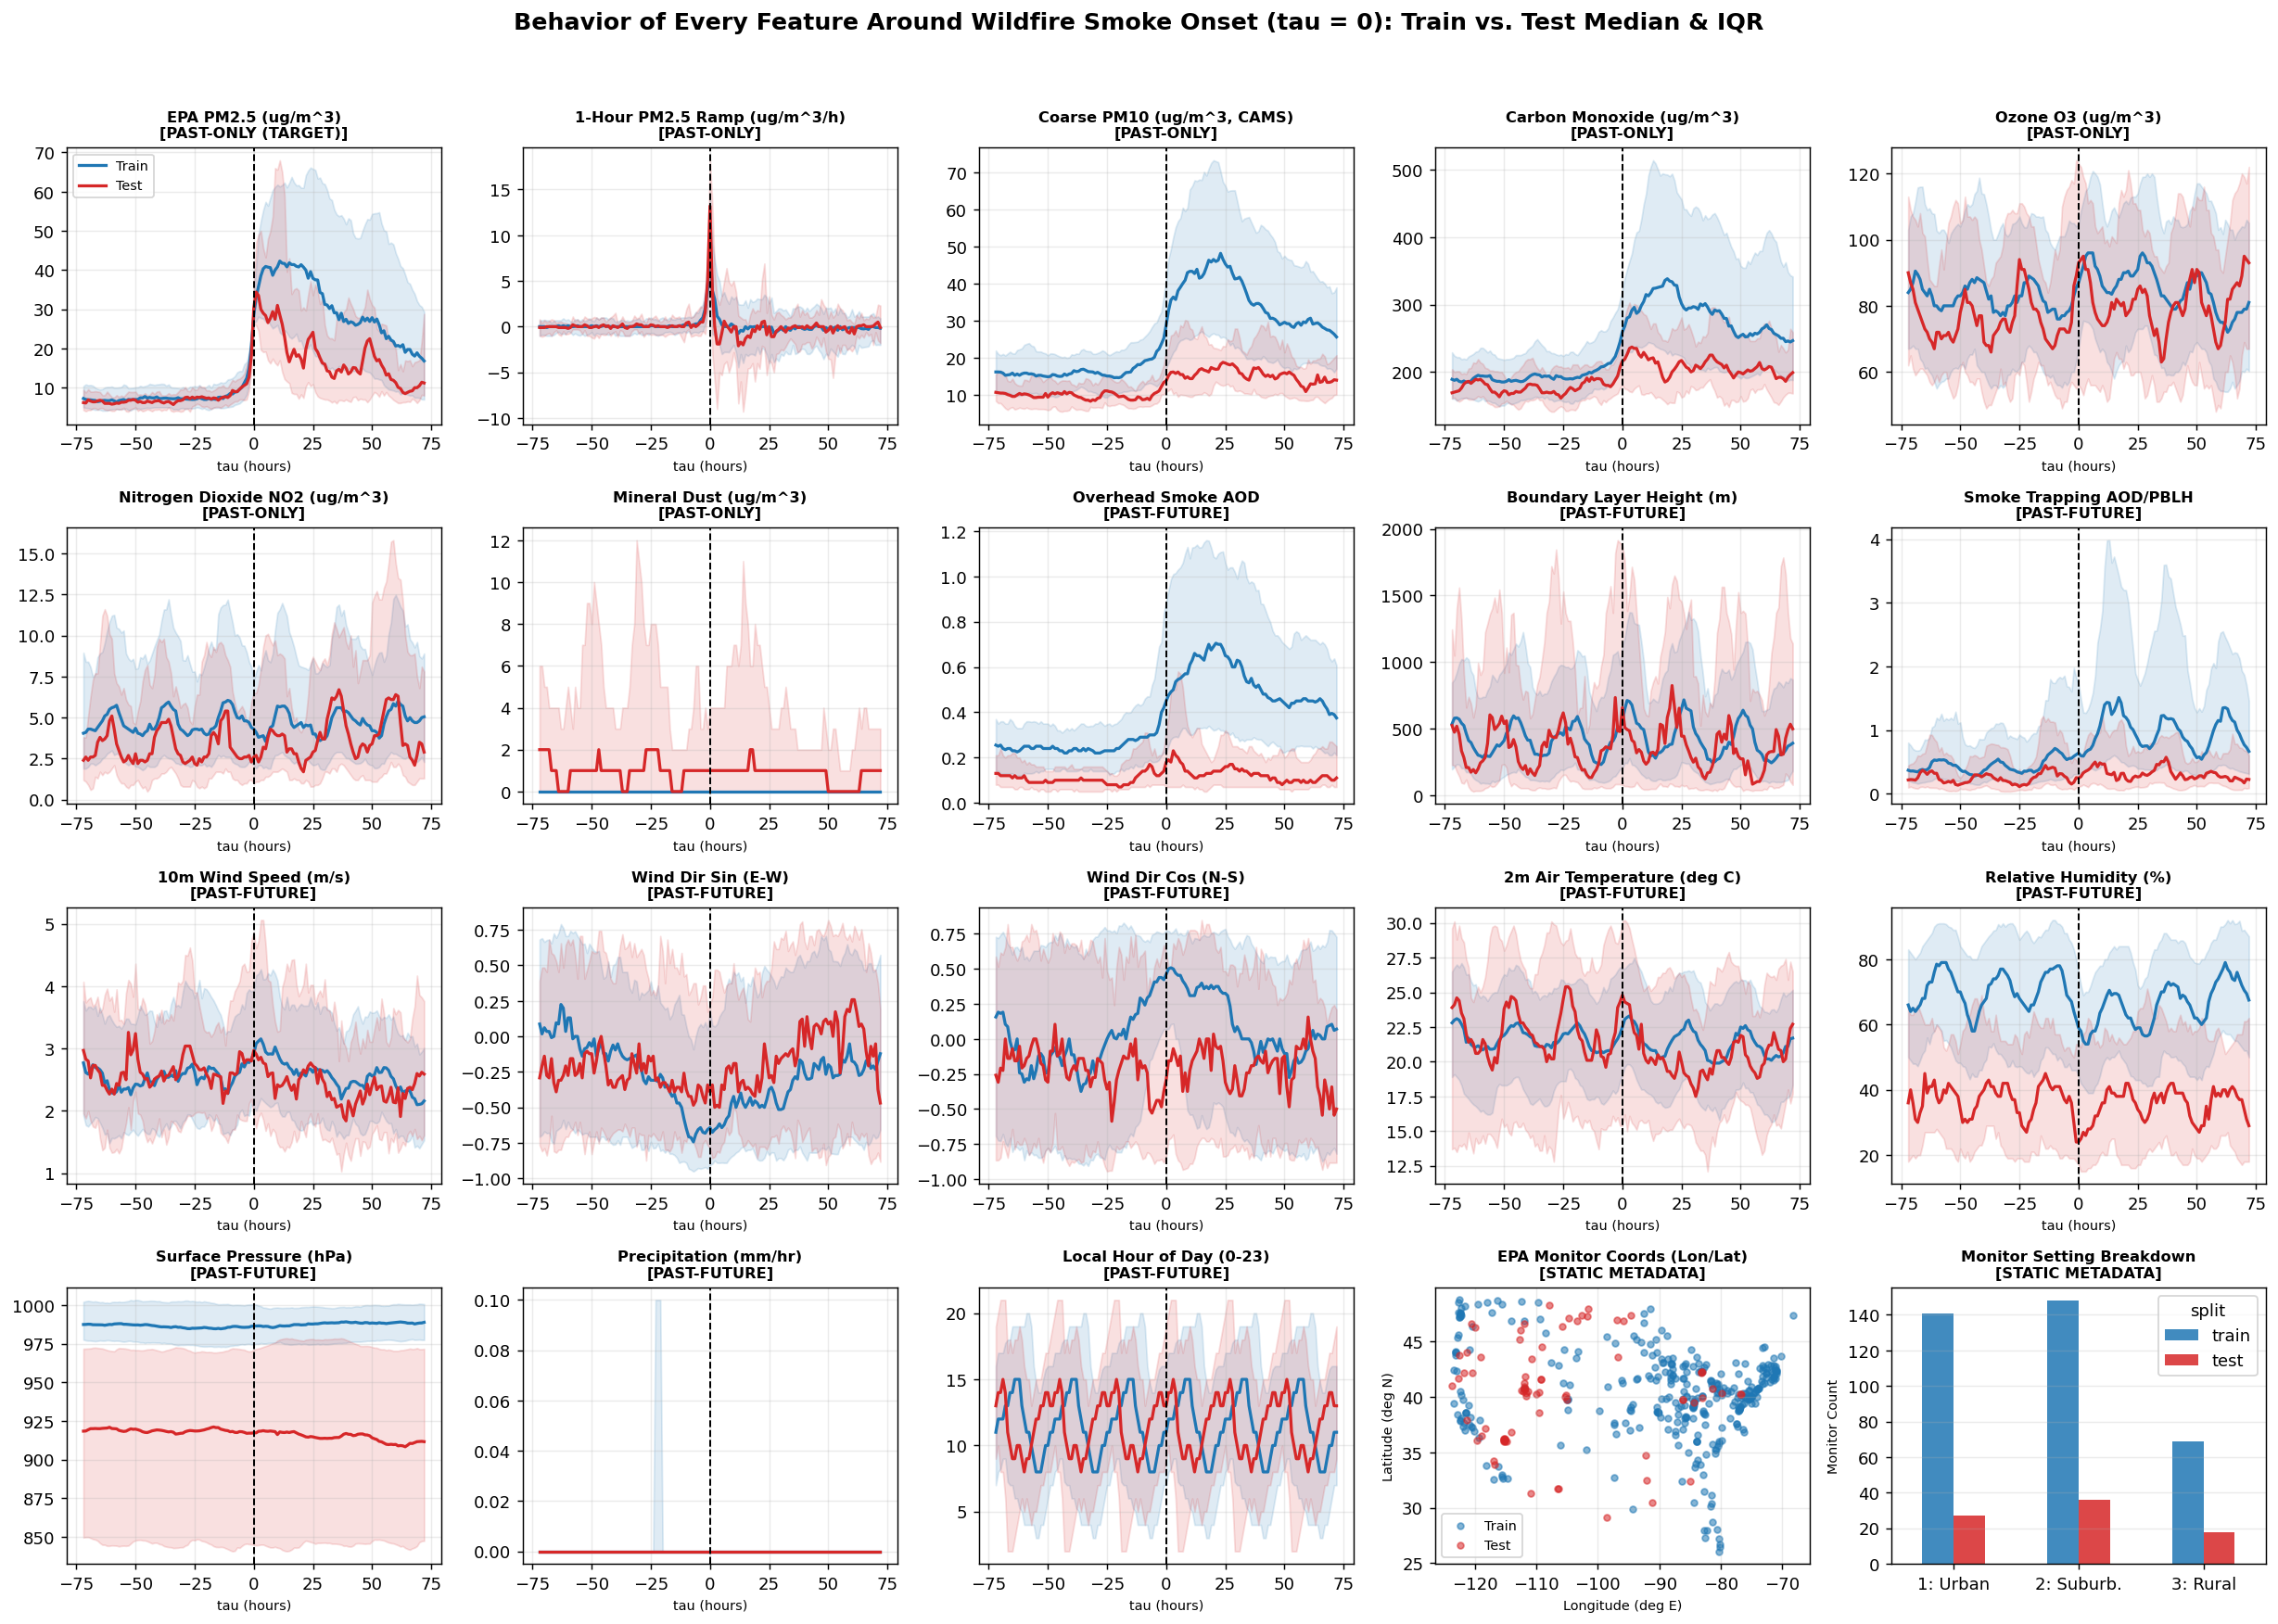

In [3]:
# Human-readable labels & units for all 18 dynamic features (7 past-only + 11 past-future)
FEATURES = [
    ('pm25_ug_m3', 'EPA PM2.5 (ug/m^3)', 'PAST-ONLY (TARGET)'),
    ('pm25_change_1h', '1-Hour PM2.5 Ramp (ug/m^3/h)', 'PAST-ONLY'),
    ('pm10_cams_ug_m3', 'Coarse PM10 (ug/m^3, CAMS)', 'PAST-ONLY'),
    ('co_ug_m3', 'Carbon Monoxide (ug/m^3)', 'PAST-ONLY'),
    ('ozone_ug_m3', 'Ozone O3 (ug/m^3)', 'PAST-ONLY'),
    ('no2_ug_m3', 'Nitrogen Dioxide NO2 (ug/m^3)', 'PAST-ONLY'),
    ('dust_ug_m3', 'Mineral Dust (ug/m^3)', 'PAST-ONLY'),
    ('aerosol_optical_depth', 'Overhead Smoke AOD', 'PAST-FUTURE'),
    ('boundary_layer_height_m', 'Boundary Layer Height (m)', 'PAST-FUTURE'),
    ('smoke_trapping_index', 'Smoke Trapping AOD/PBLH', 'PAST-FUTURE'),
    ('wind_ms', '10m Wind Speed (m/s)', 'PAST-FUTURE'),
    ('wind_dir_sin', 'Wind Dir Sin (E-W)', 'PAST-FUTURE'),
    ('wind_dir_cos', 'Wind Dir Cos (N-S)', 'PAST-FUTURE'),
    ('temp_c', '2m Air Temperature (deg C)', 'PAST-FUTURE'),
    ('humidity_pct', 'Relative Humidity (%)', 'PAST-FUTURE'),
    ('pressure_hpa', 'Surface Pressure (hPa)', 'PAST-FUTURE'),
    ('rain_mm_hr', 'Precipitation (mm/hr)', 'PAST-FUTURE'),
    ('local_hour', 'Local Hour of Day (0-23)', 'PAST-FUTURE'),
]

fig, axes = plt.subplots(4, 5, figsize=(19, 13.5), dpi=130)
axes = axes.flatten()

for idx, (col, label, role) in enumerate(FEATURES):
    ax = axes[idx]
    for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
        sub = df[df['split'] == split_name]
        g = sub.groupby('tau_hour')[col].agg(
            med='median',
            q25=lambda s: np.percentile(s, 25),
            q75=lambda s: np.percentile(s, 75),
        ).reset_index()
        ax.plot(g['tau_hour'], g['med'], color=color, lw=1.8, label=name)
        ax.fill_between(g['tau_hour'], g['q25'], g['q75'], color=color, alpha=0.14)

    ax.axvline(0, color='black', ls='--', lw=1.1)
    ax.set_title(f'{label}\n[{role}]', fontsize=9.0, fontweight='bold')
    ax.set_xlabel('tau (hours)', fontsize=8)
    ax.grid(True, alpha=0.25)
    if idx == 0:
        ax.legend(loc='upper left', fontsize=8)

# Use final 2 slots cleanly for station map and urban/suburban/rural breakdown
meta_u = df.drop_duplicates('sample_id')
ax_s1 = axes[18]
for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
    sub = meta_u[meta_u['split'] == split_name]
    ax_s1.scatter(sub['longitude'], sub['latitude'], s=14, alpha=0.55, color=color, label=name)
ax_s1.set_title('EPA Monitor Coords (Lon/Lat)\n[STATIC METADATA]', fontsize=9.0, fontweight='bold')
ax_s1.set_xlabel('Longitude (deg E)', fontsize=8)
ax_s1.set_ylabel('Latitude (deg N)', fontsize=8)
ax_s1.grid(True, alpha=0.25)
ax_s1.legend(loc='lower left', fontsize=8)

ax_s2 = axes[19]
sc = pd.crosstab(meta_u['setting_code'], meta_u['split']).reindex([1, 2, 3]).fillna(0)[['train', 'test']]
sc.index = ['1: Urban', '2: Suburb.', '3: Rural']
sc.plot(kind='bar', color=['#1f77b4', '#d62728'], alpha=0.85, ax=ax_s2, rot=0)
ax_s2.set_title('Monitor Setting Breakdown\n[STATIC METADATA]', fontsize=9.0, fontweight='bold')
ax_s2.set_ylabel('Monitor Count', fontsize=8)
ax_s2.grid(True, axis='y', alpha=0.25)

plt.suptitle(
    'Behavior of Every Feature Around Wildfire Smoke Onset (tau = 0): Train vs. Test Median & IQR',
    fontsize=14,
    fontweight='bold',
    y=0.995,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('data/wildfire_smoke_all_features_around_surge.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Detailed Single-Monitor Walkthrough Across Key Features

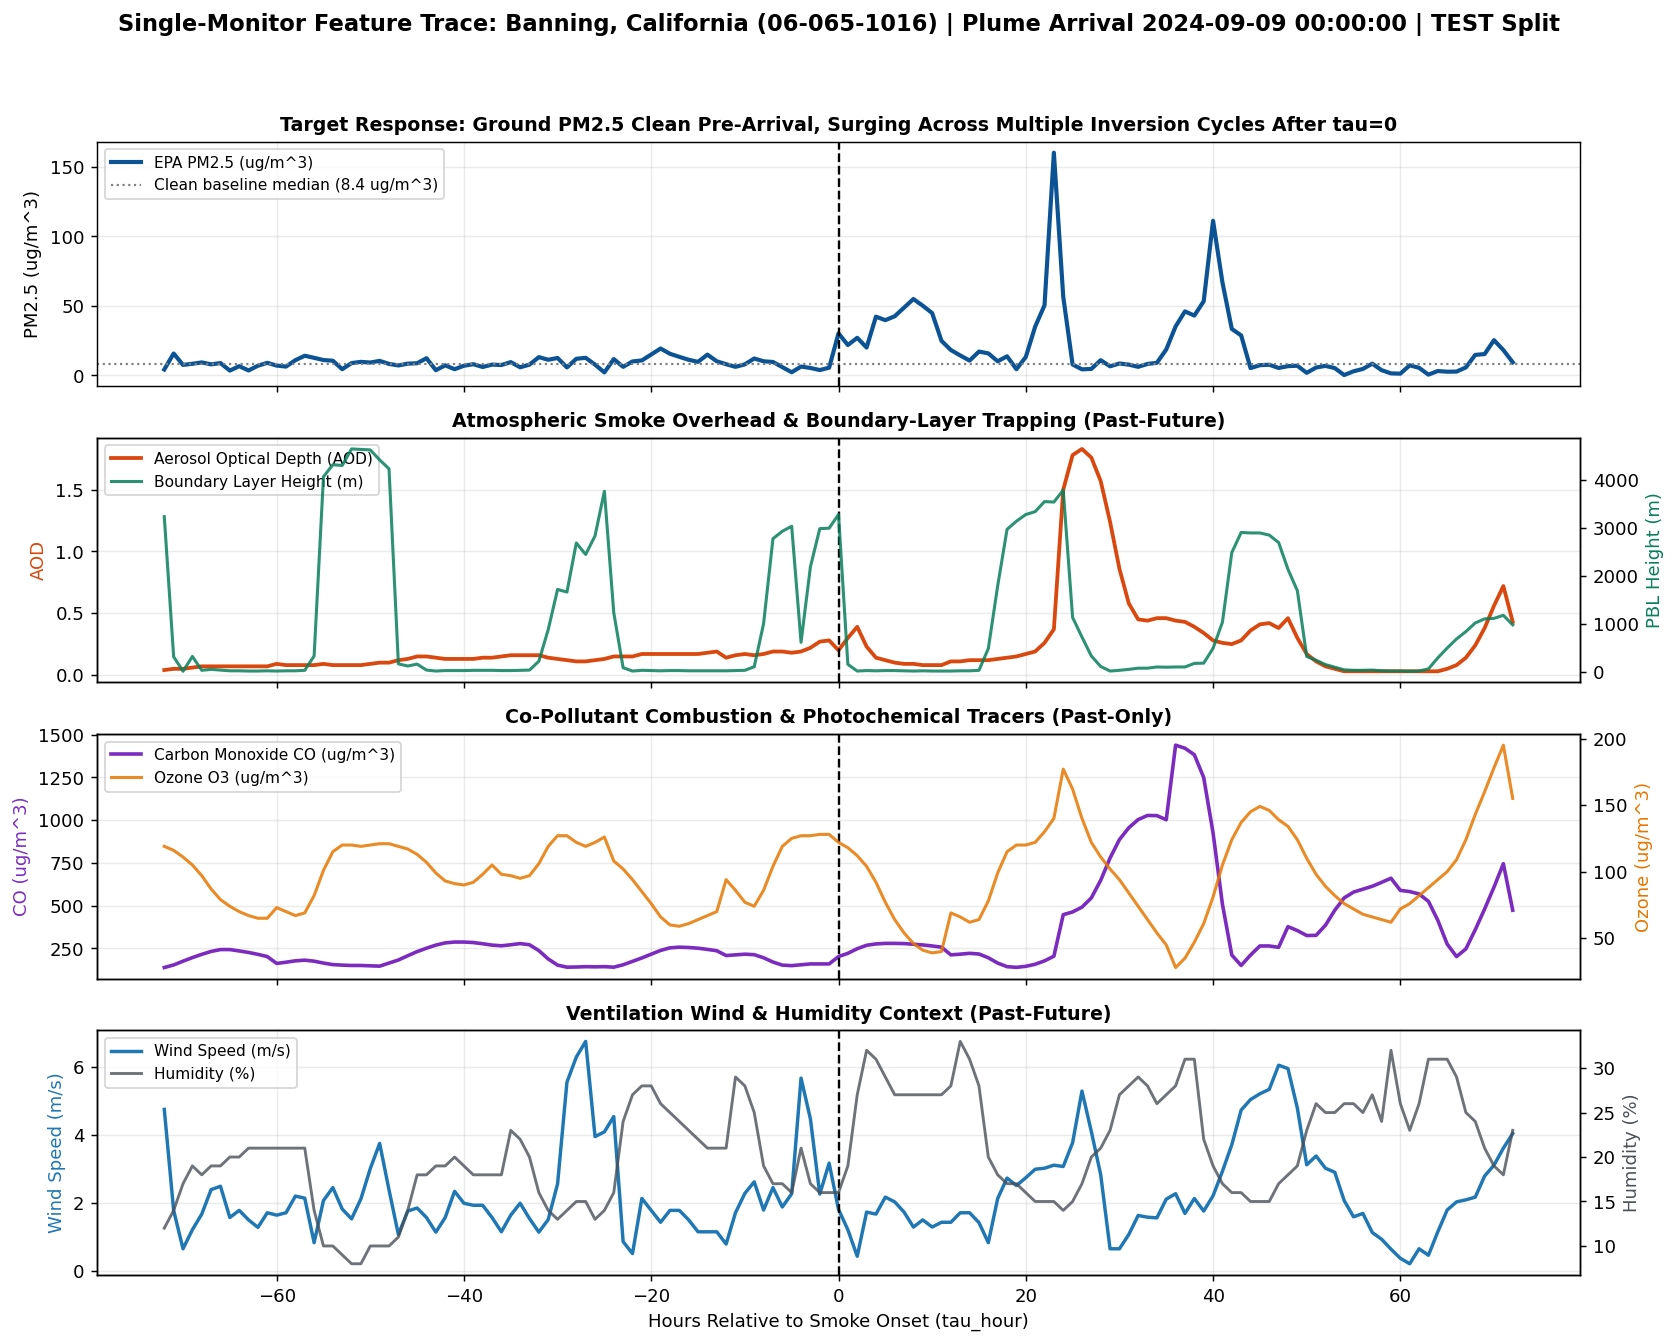

In [4]:
# Pick a dramatic Test-split monitor: Banning, CA (06-065-1016, Sept 2024 Line Fire smoke)
sample = df[df['site_id'] == '06-065-1016'].sort_values('tau_hour')
meta_r = sample.iloc[0]

fig, axes = plt.subplots(4, 1, figsize=(13, 10.5), dpi=130, sharex=True)
fig.suptitle(
    f'Single-Monitor Feature Trace: {meta_r["city"]}, {meta_r["state"]} ({meta_r["site_id"]}) | '
    f'Plume Arrival {meta_r["onset_utc"]} | {meta_r["split"].upper()} Split',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# 1. Ground EPA PM2.5 concentration
axes[0].plot(sample['tau_hour'], sample['pm25_ug_m3'], color='#0b5394', lw=2.3, label='EPA PM2.5 (ug/m^3)')
axes[0].axhline(meta_r['pre_med_pm25'], color='gray', ls=':', lw=1.2, label=f'Clean baseline median ({meta_r["pre_med_pm25"]:.1f} ug/m^3)')
axes[0].set_ylabel('PM2.5 (ug/m^3)')
axes[0].set_title('Target Response: Ground PM2.5 Clean Pre-Arrival, Surging Across Multiple Inversion Cycles After tau=0', fontweight='bold', fontsize=10.5)
axes[0].legend(loc='upper left', fontsize=8.5)

# 2. Overhead smoke AOD & trapping height (Past-Future dispersion drivers)
ax1_r = axes[1].twinx()
l_aod, = axes[1].plot(sample['tau_hour'], sample['aerosol_optical_depth'], color='#d9480f', lw=2.1, label='Aerosol Optical Depth (AOD)')
l_pbl, = ax1_r.plot(sample['tau_hour'], sample['boundary_layer_height_m'], color='#087f5b', lw=1.7, alpha=0.85, label='Boundary Layer Height (m)')
axes[1].set_ylabel('AOD', color='#d9480f')
ax1_r.set_ylabel('PBL Height (m)', color='#087f5b')
axes[1].set_title('Atmospheric Smoke Overhead & Boundary-Layer Trapping (Past-Future)', fontweight='bold', fontsize=10.5)
axes[1].legend([l_aod, l_pbl], [l_aod.get_label(), l_pbl.get_label()], loc='upper left', fontsize=8.5)

# 3. Chemical combustion plume tracers (Past-Only)
ax2_r = axes[2].twinx()
l_co, = axes[2].plot(sample['tau_hour'], sample['co_ug_m3'], color='#7b2cbf', lw=2.0, label='Carbon Monoxide CO (ug/m^3)')
l_o3, = ax2_r.plot(sample['tau_hour'], sample['ozone_ug_m3'], color='#e67700', lw=1.7, alpha=0.85, label='Ozone O3 (ug/m^3)')
axes[2].set_ylabel('CO (ug/m^3)', color='#7b2cbf')
ax2_r.set_ylabel('Ozone (ug/m^3)', color='#e67700')
axes[2].set_title('Co-Pollutant Combustion & Photochemical Tracers (Past-Only)', fontweight='bold', fontsize=10.5)
axes[2].legend([l_co, l_o3], [l_co.get_label(), l_o3.get_label()], loc='upper left', fontsize=8.5)

# 4. Wind speed & humidity
ax3_r = axes[3].twinx()
l_w, = axes[3].plot(sample['tau_hour'], sample['wind_ms'], color='#1f77b4', lw=1.9, label='Wind Speed (m/s)')
l_rh, = ax3_r.plot(sample['tau_hour'], sample['humidity_pct'], color='#495057', lw=1.6, alpha=0.8, label='Humidity (%)')
axes[3].set_ylabel('Wind Speed (m/s)', color='#1f77b4')
ax3_r.set_ylabel('Humidity (%)', color='#495057')
axes[3].set_xlabel('Hours Relative to Smoke Onset (tau_hour)')
axes[3].set_title('Ventilation Wind & Humidity Context (Past-Future)', fontweight='bold', fontsize=10.5)
axes[3].legend([l_w, l_rh], [l_w.get_label(), l_rh.get_label()], loc='upper left', fontsize=8.5)

for a in axes:
    a.axvline(0, color='black', ls='--', lw=1.3)
    a.grid(True, alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('data/wildfire_smoke_single_region_features.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Before vs. After $\tau = 0$: Numerical Comparison Across All Monitors

In [5]:
before = df[df['tau_hour'] < 0]
after = df[df['tau_hour'] >= 0]

rows = []
for col, label, role in FEATURES:
    pre_med = before[col].median()
    post_med = after[col].median()
    pre_peak = before.groupby('sample_id')[col].max().median()
    post_peak = after.groupby('sample_id')[col].max().median()
    rows.append({
        'Feature': col,
        'Role': role,
        'Pre-Onset Median': round(pre_med, 2),
        'Post-Onset Median': round(post_med, 2),
        'Pre-Onset Peak Median': round(pre_peak, 2),
        'Post-Onset Peak Median': round(post_peak, 2),
        'Median Shift': round(post_med - pre_med, 2),
    })

summary_tbl = pd.DataFrame(rows)
display(summary_tbl)

,Feature,Role,Pre-Onset Median,Post-Onset Median,Pre-Onset Peak Median,Post-Onset Peak Median,Median Shift
0,pm25_ug_m3,PAST-ONLY (TARGET),7.35,27.60,22.00,89.80,20.25
1,pm25_change_1h,PAST-ONLY,0.00,0.00,8.10,31.50,0.00
2,pm10_cams_ug_m3,PAST-ONLY,14.80,29.90,32.00,75.70,15.10
3,co_ug_m3,PAST-ONLY,191.00,263.00,294.00,470.00,72.00
4,ozone_ug_m3,PAST-ONLY,82.00,85.00,131.00,142.00,3.00
5,no2_ug_m3,PAST-ONLY,4.40,4.50,16.90,19.20,0.10
6,dust_ug_m3,PAST-ONLY,0.00,0.00,1.00,1.00,0.00
7,aerosol_optical_depth,PAST-FUTURE,0.22,0.42,0.58,1.16,0.20
8,boundary_layer_height_m,PAST-FUTURE,395.00,395.00,1965.00,2035.00,0.00
9,smoke_trapping_index,PAST-FUTURE,0.38,0.76,2.64,5.45,0.37
